# 03 — End-to-end day-ahead load forecasting for Germany

Data → data check → leakage-safe features → models → rolling backtest → evaluation →
significance → error analysis → uncertainty → explainability.

**Forecasting task.** At **09:00 UTC on day D-1** (≈ when the German TSOs publish theirs),
forecast all 24 hourly loads of UTC day D. The newest load value available is the hour starting
07:00 UTC on D-1, so target hours are 17–40 h after the last observation.

**Evaluation.** Monthly refits with an expanding window; hyperparameters tuned on 2018 only;
test on **2019** (normal year) and **Jan–Sep 2020** (COVID stress test). Benchmarks: naive
baselines, the TSOs' official day-ahead forecast and a bias-corrected version of it.

All logic lives in `src/energy_demand_forecasting/`; this notebook orchestrates and analyses.
The heavy backtest (~35 min) is produced by `uv run run-backtest` and loaded here; set
`RUN_FULL_PIPELINE = True` to recompute it inside the notebook.

In [1]:
RUN_FULL_PIPELINE = False

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from energy_demand_forecasting import pipeline
from energy_demand_forecasting.data import PROJECT_ROOT
from energy_demand_forecasting.evaluation import PERIODS
from energy_demand_forecasting.features import (
    TARGET,
    TSO_FORECAST,
    calendar_features,
    load_dataset,
)
from energy_demand_forecasting.forecast_features import (
    ORIGIN_OFFSET,
    build_features,
)
from energy_demand_forecasting.models import LGBMForecaster, _normalise

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
FIG, RES = PROJECT_ROOT / "reports" / "figures", PROJECT_ROOT / "reports" / "results"
save = lambda fig, name: fig.savefig(FIG / f"{name}.png")

df = load_dataset()
print(df.shape, df.index.min(), "->", df.index.max())

(50400, 24) 2015-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00


## 1. Data and data-quality check

Target: `DE_load_actual_entsoe_transparency` (ENTSO-E, via OPSD). Comparing its annual totals
with official German gross electricity consumption shows its **coverage drifts upward**
(≈81 % → 86 %) — the series is not a fixed share of national demand. That matters for how we
read the TSO forecast's bias.

,entsoe_actual_TWh,tso_forecast_TWh,official_gross_TWh,coverage_ratio,actual_yoy_%,official_yoy_%,tso_bias_GW
utc_timestamp,,,,,,,
2015,479.496,475.361,595.100,0.806,NaN,NaN,0.472
2016,486.995,473.303,594.700,0.819,1.564,-0.067,1.559
2017,492.116,488.183,NaN,NaN,1.052,NaN,0.449
2018,498.895,493.333,584.189,0.854,1.377,NaN,0.475
2019,490.475,478.794,569.000,0.862,-1.688,-2.600,1.333


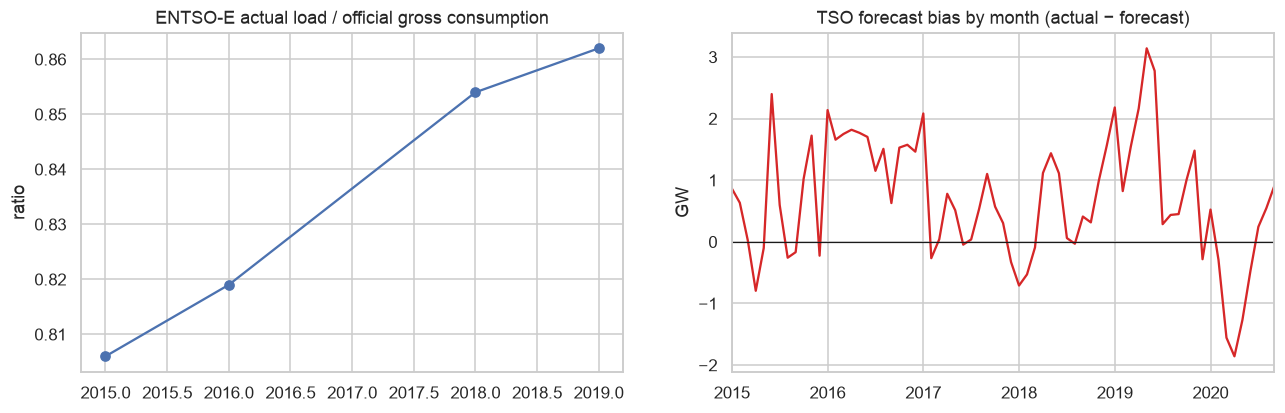

In [2]:
check = pd.read_csv(RES / "data_check_annual.csv", index_col=0)
display(check)
err = (df[TARGET] - df[TSO_FORECAST]) / 1000
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
check["coverage_ratio"].dropna().plot(ax=axes[0], marker="o")
axes[0].set(
    title="ENTSO-E actual load / official gross consumption", ylabel="ratio", xlabel=""
)
err.resample("ME").mean().plot(ax=axes[1], color="tab:red")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(
    title="TSO forecast bias by month (actual − forecast)", ylabel="GW", xlabel=""
)
save(fig, "10_data_check")

## 2. Leakage-safe features

Calendar (local time, DST-aware), population-weighted holiday share, bridge days, distance
to holidays, holiday-cleaned weekly lag, load lags ≥ 48 h, load state at the issue-time origin
(last value, 24 h / 7 d / 28 d means), and weather (population-weighted means, per-city
temperature, heating/cooling degree-hours, smoothed temperature for thermal inertia).

**Leakage test:** multiply every load value after the issue-time cut-off by 3 — features for the
target day must not change.

In [3]:
X, y = build_features(df, "actual")
print(f"{X.shape[1]} features:", ", ".join(X.columns))

D = pd.Timestamp("2019-05-15", tz="UTC")
tampered = df.copy()
tampered.loc[tampered.index > D - ORIGIN_OFFSET, TARGET] *= 3
X_t, _ = build_features(tampered, "actual")
day = slice(D, D + pd.Timedelta(hours=23))
print(
    "Features for",
    D.date(),
    "unchanged after tampering with the future:",
    X.loc[day].fillna(-1).equals(X_t.loc[day].fillna(-1)),
)

38 features: hour, dow, month, is_weekend, holiday_share, is_xmas_period, doy_sin, doy_cos, bridge_share, days_since_hol, days_to_hol, hol_lag48, hol_lag168, lag48, lag72, lag168, lag336, lag168_clean, last_load, mean_last24, mean_last168, level28, w_temperature_2m, w_relative_humidity_2m, w_wind_speed_10m, w_cloud_cover, w_shortwave_radiation, temp_berlin, temp_hamburg, temp_munich, temp_cologne, temp_frankfurt, hdd, cdd, temp_ewm24, temp_ewm72, temp_daymean, temp_lag24
Features for 2019-05-15 unchanged after tampering with the future: True


## 3. Models and rolling backtest

| Model | Idea |
|---|---|
| `naive_2day`, `snaive_week`, `weekday_mean_4w` | naive references |
| `tso` / `tso_bias_corrected` | official TSO forecast; + its trailing 28-day mean error (known at issue time) |
| `ridge` | linear model, 24×3 hour × day-type profile, normalised target |
| `lgbm_raw` | LightGBM on load in MW |
| `lgbm_norm` | LightGBM on load / 28-day level (handles trend, coverage drift, COVID) |
| `ensemble` | mean of the two LightGBMs |
| `q10`, `q90` | quantile LightGBM → 80 % prediction interval |

Weather variants: **`actual`** (reanalysis = perfect weather forecast, optimistic),
**`noisy`** (trained on actuals, tested with simulated day-ahead forecast errors — *the
realistic setting and our headline*), **`none`** (no weather at all).

In [4]:
params = json.loads((RES / "best_params.json").read_text())
display(pd.DataFrame(params).T)
if RUN_FULL_PIPELINE:
    preds = pipeline.run(tune=False)
else:
    preds = pd.read_parquet(pipeline.PRED_PATH)
print(preds.shape, preds.index.min(), "->", preds.index.max())

,alpha,val_MAE,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,n_trials
ridge,0.1,1277.963363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lgbm_raw,NaN,980.605163,1500.0,0.029851,156.0,188.0,0.897413,0.504440,1.242288,20.0
lgbm_norm,NaN,988.341117,1500.0,0.039307,182.0,187.0,0.904590,0.543673,0.133533,20.0


(15336, 28) 2019-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00


## 4. Headline results

,,MAE_GW,RMSE_GW,MAPE_%,peak_MAE_GW
period,model,,,,
test_2019,snaive_week,2.558,4.465,4.74,2.711
stress_2020,snaive_week,2.227,3.778,4.30,2.453
test_2019,tso,1.989,2.489,3.52,2.140
stress_2020,tso,1.459,1.892,2.81,1.533
test_2019,tso_bias_corrected,1.553,1.986,2.87,1.647
stress_2020,tso_bias_corrected,1.297,1.731,2.46,1.487
test_2019,ridge,1.353,1.925,2.54,1.312
stress_2020,ridge,1.277,1.665,2.46,1.385
test_2019,lgbm_raw__noisy,1.020,1.307,1.88,1.026


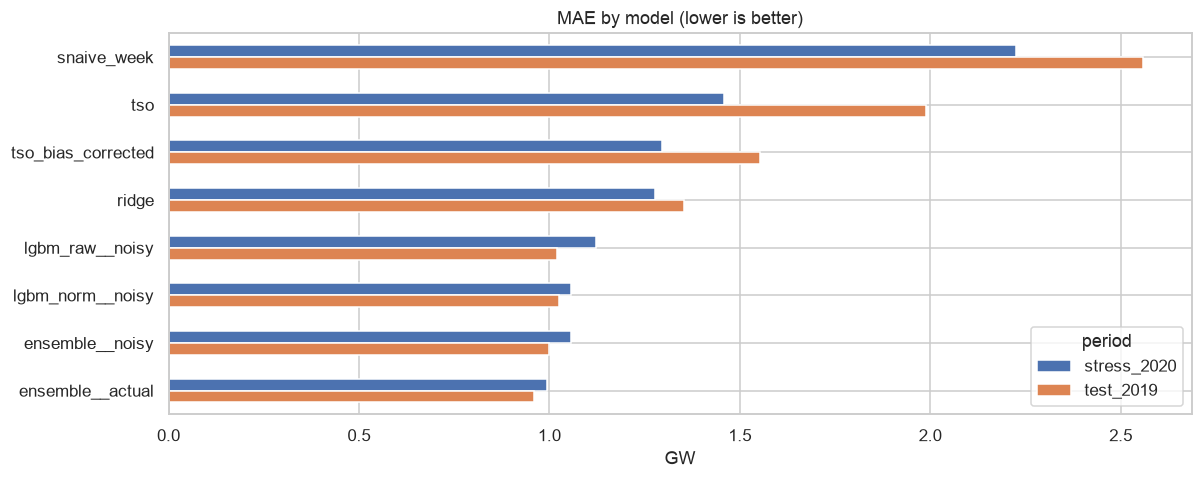

In [5]:
m = pd.read_csv(RES / "metrics.csv", index_col=[0, 1])
headline = [
    "snaive_week",
    "tso",
    "tso_bias_corrected",
    "ridge",
    "lgbm_raw__noisy",
    "lgbm_norm__noisy",
    "ensemble__noisy",
    "ensemble__actual",
]
tbl = m.loc[(slice(None), headline), ["MAE", "RMSE", "MAPE_%", "peak_MAE"]].copy()
tbl[["MAE", "RMSE", "peak_MAE"]] = (tbl[["MAE", "RMSE", "peak_MAE"]] / 1000).round(3)
tbl = tbl.rename(
    columns={"MAE": "MAE_GW", "RMSE": "RMSE_GW", "peak_MAE": "peak_MAE_GW"}
)
display(tbl)

plot = m["MAE"].unstack(0).loc[headline] / 1000
fig, ax = plt.subplots(figsize=(12, 4.5))
plot.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set(title="MAE by model (lower is better)", xlabel="GW", ylabel="")
save(fig, "11_headline_mae")

In [6]:
full = m[["MAE", "RMSE", "MAPE_%", "peak_MAE"]].unstack(0)
full.columns = [f"{a}|{b}" for a, b in full.columns]
full.sort_values("MAE|test_2019").round(1)

,MAE|stress_2020,MAE|test_2019,RMSE|stress_2020,RMSE|test_2019,MAPE_%|stress_2020,MAPE_%|test_2019,peak_MAE|stress_2020,peak_MAE|test_2019
model,,,,,,,,
ensemble__actual,994.2,958.3,1330.4,1237.9,1.9,1.8,986.9,974.7
lgbm_norm__actual,1001.6,978.8,1345.8,1273.0,1.9,1.8,1044.3,1027.7
lgbm_raw__actual,1056.3,980.6,1399.5,1263.4,2.0,1.8,1035.9,977.4
ensemble__noisy,1056.2,1000.0,1409.2,1284.6,2.0,1.8,1047.4,1017.1
lgbm_raw__noisy,1122.1,1020.5,1484.5,1306.5,2.2,1.9,1077.5,1026.2
lgbm_norm__noisy,1055.9,1024.8,1414.2,1322.2,2.0,1.9,1094.4,1066.8
ensemble__none,1125.4,1126.1,1451.4,1425.9,2.1,2.0,1184.4,1172.5
lgbm_raw__none,1210.3,1144.3,1551.3,1448.2,2.3,2.1,1254.6,1191.3
lgbm_norm__none,1119.3,1157.4,1446.4,1469.3,2.1,2.1,1190.4,1206.6


## 5. How much does weather (and weather-forecast error) matter?

period,stress_2020,test_2019
weather,,
none,1.125,1.126
noisy,1.056,1.000
actual,0.994,0.958


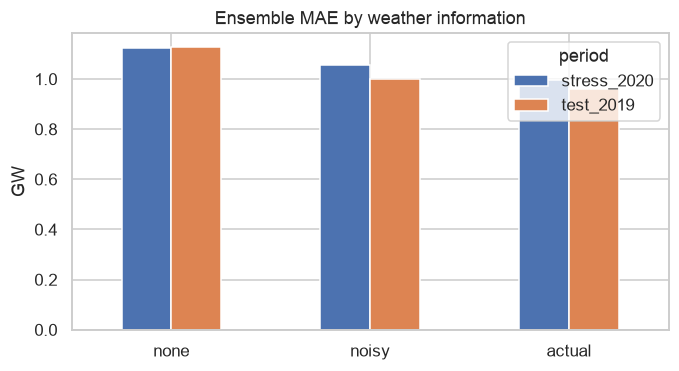

In [7]:
rows = []
for v in ["none", "noisy", "actual"]:
    for p in PERIODS:
        rows.append(
            {
                "weather": v,
                "period": p,
                "ensemble_MAE_GW": m.loc[(p, f"ensemble__{v}"), "MAE"] / 1000,
            }
        )
wv = (
    pd.DataFrame(rows)
    .pivot(index="weather", columns="period", values="ensemble_MAE_GW")
    .loc[["none", "noisy", "actual"]]
)
display(wv.round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
wv.plot.bar(ax=ax, rot=0)
ax.set(title="Ensemble MAE by weather information", ylabel="GW", xlabel="")
save(fig, "12_weather_variants")

## 6. Are the differences statistically significant?

Diebold-Mariano test on daily mean absolute errors (Newey-West variance, HLN correction).
Negative statistic ⇒ our model is more accurate than the reference.

In [8]:
dm = pd.read_csv(RES / "dm_tests.csv")
dm["mean_diff_GW"] = (dm["mean_diff_MW"] / 1000).round(3)
dm.pivot_table(
    index=["period", "model"], columns="vs", values=["mean_diff_GW", "p_value"]
).round(4)

mean_diff_GW                     \
vs                                  ridge snaive_week    tso   
period      model                                              
stress_2020 ensemble__actual       -0.283      -1.232 -0.465   
            ensemble__noisy        -0.221      -1.170 -0.403   
            ensemble__none         -0.152      -1.101 -0.333   
test_2019   ensemble__actual       -0.395      -1.600 -1.031   
            ensemble__noisy        -0.353      -1.558 -0.989   
            ensemble__none         -0.227      -1.432 -0.863   

                                                p_value                   \
vs                           tso_bias_corrected   ridge snaive_week  tso   
period      model                                                          
stress_2020 ensemble__actual             -0.302  0.0000         0.0  0.0   
            ensemble__noisy              -0.240  0.0000         0.0  0.0   
            ensemble__none               -0.171  0.0073         0.0  0.0   
test_2019   ensemble__actual             -0.594  0.0000         0.0  0.0   
            ensemble__noisy              -0.553  0.0001         0.0  0.0   
            ensemble__none               -0.427  0.0155         0.0  0.0   

                                                 
vs                           tso_bias_corrected  
period      model                                
stress_2020 ensemble__actual             0.0000  
            ensemble__noisy              0.0000  
            ensemble__none               0.0273  
test_2019   ensemble__actual             0.0000  
            ensemble__noisy              0.0000  
            ensemble__none               0.0000

## 7. Error analysis (2019, realistic weather)

,ensemble (noisy wx),TSO,TSO bias-corr.
christmas,1.538,2.078,2.309
holiday,1.476,1.497,2.259
weekend,0.947,1.362,1.659
workday,0.987,2.262,1.458


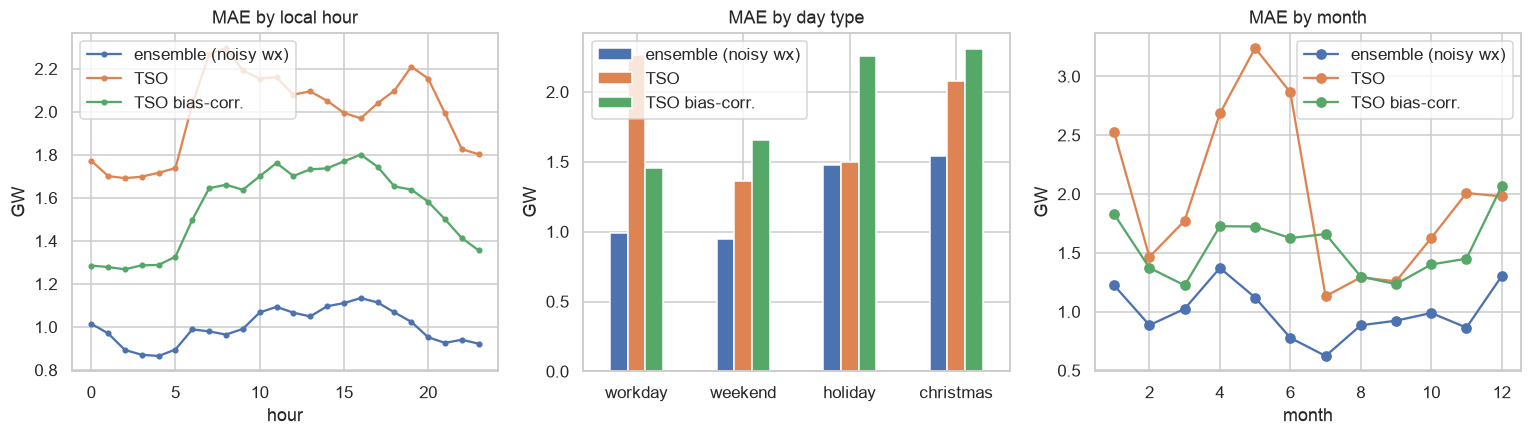

In [9]:
s, e = PERIODS["test_2019"]
P = preds.loc[s:e]
cal = calendar_features(P.index)
cols = {
    "ensemble__noisy": "ensemble (noisy wx)",
    "tso": "TSO",
    "tso_bias_corrected": "TSO bias-corr.",
}
abs_err = P[list(cols)].sub(P.actual, axis=0).abs().rename(columns=cols) / 1000
day_type = pd.Series("workday", index=P.index)
day_type[cal.is_weekend == 1] = "weekend"
day_type[cal.holiday_share >= 0.5] = "holiday"
day_type[cal.is_xmas_period == 1] = "christmas"

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
abs_err.groupby(cal.hour).mean().plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="MAE by local hour", xlabel="hour", ylabel="GW")
abs_err.groupby(day_type).mean().loc[
    ["workday", "weekend", "holiday", "christmas"]
].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="MAE by day type", ylabel="GW", xlabel="")
abs_err.groupby(cal.month).mean().plot(ax=axes[2], marker="o")
axes[2].set(title="MAE by month", xlabel="month", ylabel="GW")
save(fig, "13_error_breakdown")
abs_err.groupby(day_type).mean().round(3)

In [10]:
bias = P[list(cols)].rsub(P.actual, axis=0).rename(columns=cols).mean() / 1000
print("Mean bias 2019 (actual − forecast, GW):")
print(bias.round(3).to_string())
daily_err = abs_err.groupby(abs_err.index.floor("D")).mean()
print("\nWorst 8 days for the ensemble:")
daily_err.sort_values("ensemble (noisy wx)", ascending=False).head(8).round(2)

Mean bias 2019 (actual − forecast, GW):
ensemble (noisy wx)    0.030
TSO                    1.333
TSO bias-corr.        -0.129

Worst 8 days for the ensemble:


,ensemble (noisy wx),TSO,TSO bias-corr.
utc_timestamp,,,
2019-04-21 00:00:00+00:00,3.93,3.40,5.53
2019-04-20 00:00:00+00:00,3.49,1.18,3.29
2019-12-23 00:00:00+00:00,3.41,3.25,3.85
2019-12-20 00:00:00+00:00,3.07,3.31,4.38
2019-04-19 00:00:00+00:00,3.02,1.36,3.35
2019-01-09 00:00:00+00:00,2.93,4.90,3.15
2019-12-19 00:00:00+00:00,2.43,1.89,3.04
2019-04-22 00:00:00+00:00,2.39,1.70,3.54


## 8. Example forecasts

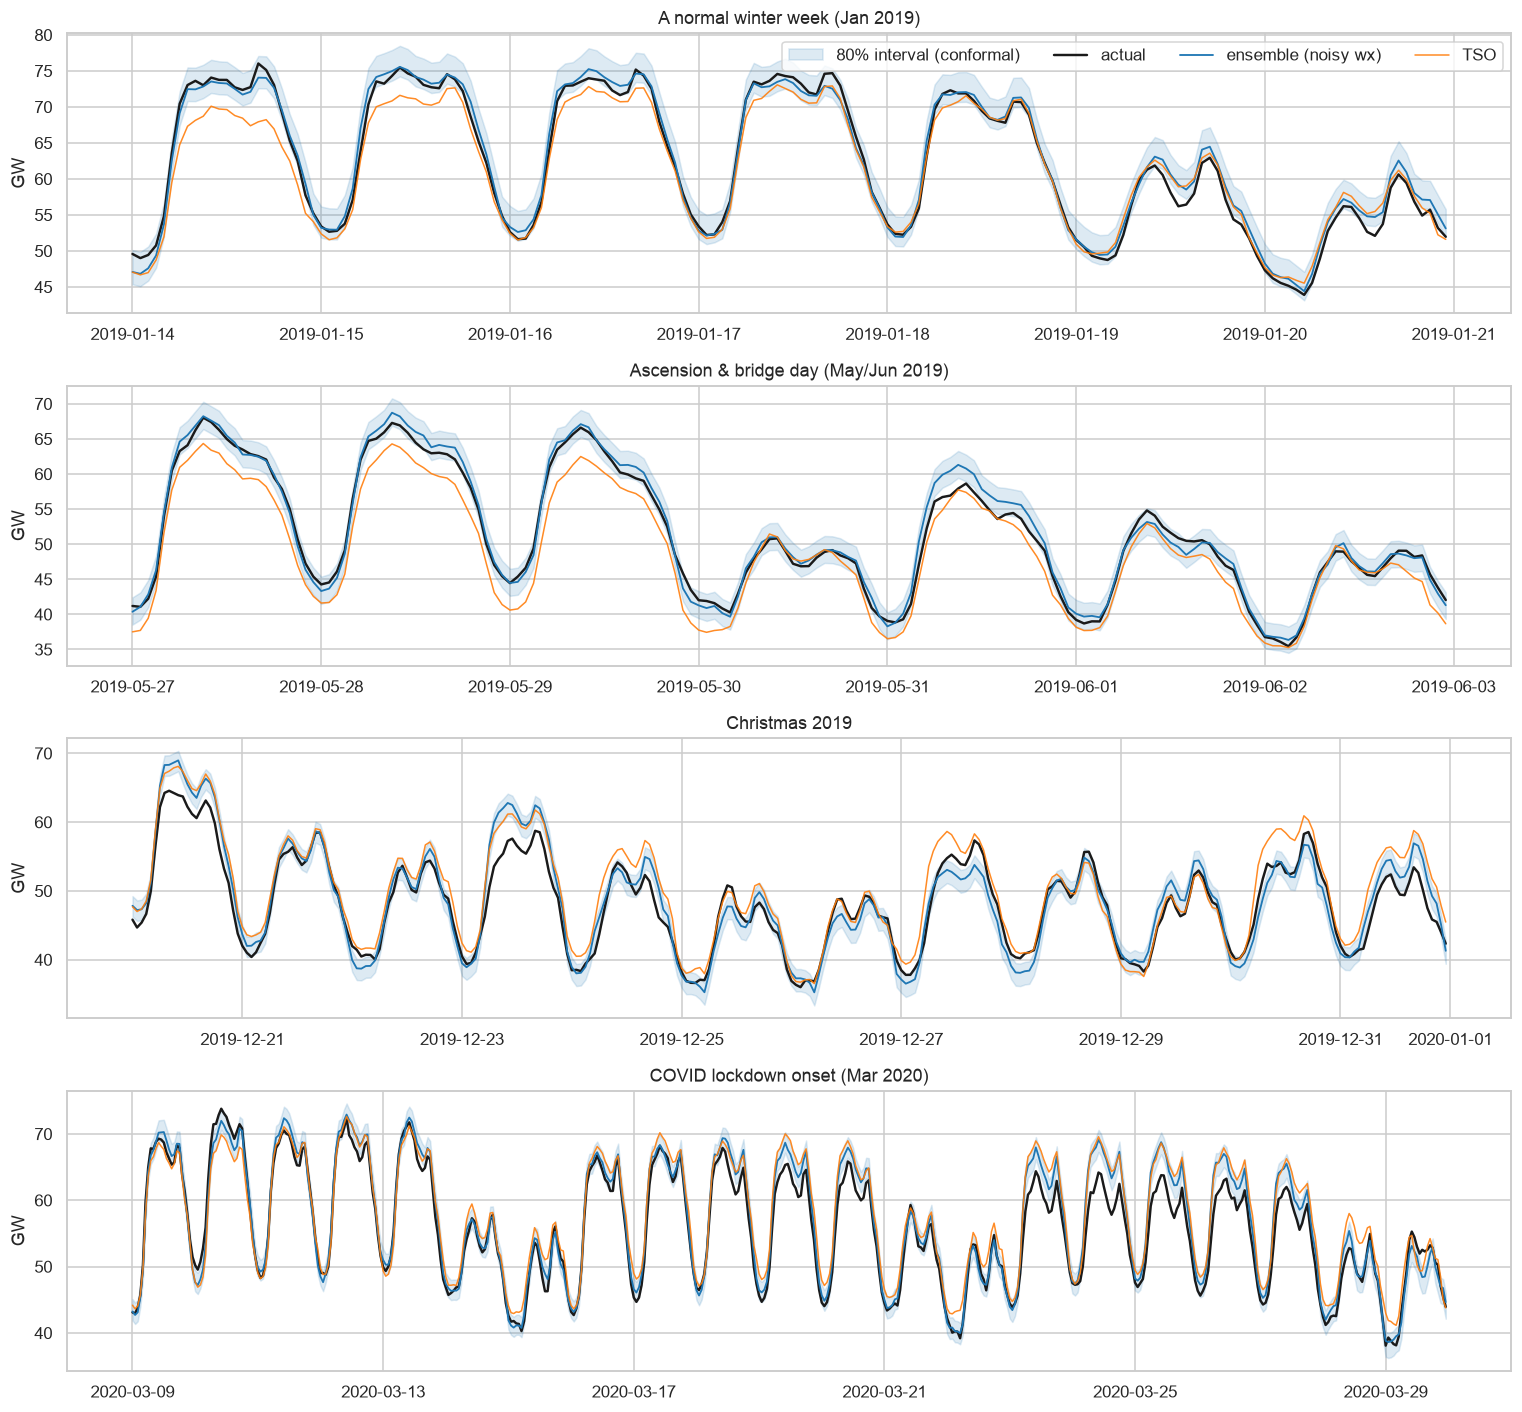

In [11]:
windows = {
    "A normal winter week (Jan 2019)": ("2019-01-14", "2019-01-20"),
    "Ascension & bridge day (May/Jun 2019)": ("2019-05-27", "2019-06-02"),
    "Christmas 2019": ("2019-12-20", "2019-12-31"),
    "COVID lockdown onset (Mar 2020)": ("2020-03-09", "2020-03-29"),
}
fig, axes = plt.subplots(len(windows), 1, figsize=(14, 13))
for ax, (title, (a, b)) in zip(axes, windows.items()):
    w = preds.loc[a : f"{b} 23:00"] / 1000
    ax.fill_between(
        w.index,
        w.q_cp_lo__noisy,
        w.q_cp_hi__noisy,
        color="tab:blue",
        alpha=0.15,
        label="80% interval (conformal)",
    )
    ax.plot(w.actual, color="k", lw=1.6, label="actual")
    ax.plot(w.ensemble__noisy, color="tab:blue", lw=1.2, label="ensemble (noisy wx)")
    ax.plot(w.tso, color="tab:orange", lw=1, alpha=0.9, label="TSO")
    ax.set(title=title, ylabel="GW")
axes[0].legend(ncols=4, loc="upper right")
fig.tight_layout()
save(fig, "14_example_forecasts")

## 9. Adapting to the COVID shock

,MAE lockdown (GW)
ensemble,1.251
LGBM raw,1.381
LGBM normalised,1.223
TSO,2.056
seasonal naive,3.084


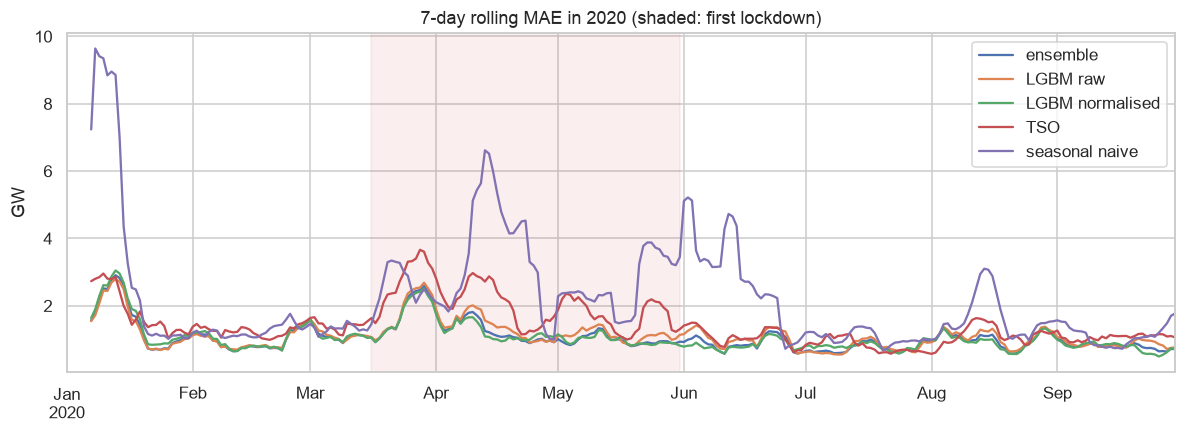

In [12]:
s20, e20 = PERIODS["stress_2020"]
c = {
    "ensemble__noisy": "ensemble",
    "lgbm_raw__noisy": "LGBM raw",
    "lgbm_norm__noisy": "LGBM normalised",
    "tso": "TSO",
    "snaive_week": "seasonal naive",
}
P20 = preds.loc[s20:e20]
roll = (
    P20[list(c)]
    .sub(P20.actual, axis=0)
    .abs()
    .rename(columns=c)
    .resample("D")
    .mean()
    .rolling(7)
    .mean()
    / 1000
)
fig, ax = plt.subplots(figsize=(13, 4))
roll.plot(ax=ax)
ax.axvspan(
    pd.Timestamp("2020-03-16", tz="UTC"),
    pd.Timestamp("2020-05-31", tz="UTC"),
    color="tab:red",
    alpha=0.08,
)
ax.set(
    title="7-day rolling MAE in 2020 (shaded: first lockdown)", ylabel="GW", xlabel=""
)
save(fig, "15_covid_adaptation")
lock = slice("2020-03-16", "2020-05-31")
(
    P20.loc[lock, list(c)].sub(P20.loc[lock, "actual"], axis=0).abs().mean() / 1000
).rename(index=c).round(3).to_frame("MAE lockdown (GW)")

## 10. Uncertainty: 80 % prediction intervals

Three methods: raw quantile LightGBM (q10/q90), **CQR** (quantiles widened by recent conformity scores) and
**conformal around the ensemble** (rolling empirical error quantiles). Calibration uses only errors known
at issue time (lagged 48 h, 56-day window), so the first week of 2019 has no interval.

coverage_%                        mean_width_GW  \
method              conformal_point    cqr quantile_lgbm conformal_point   
period      weather                                                        
stress_2020 actual            79.09  80.78         45.35            3.20   
            noisy             79.53  80.72         44.45            3.42   
test_2019   actual            78.37  79.36         43.69            2.94   
            noisy             79.16  79.61         43.60            3.17   

                                         
method                cqr quantile_lgbm  
period      weather                      
stress_2020 actual   3.59          1.63  
            noisy    3.75          1.66  
test_2019   actual   3.29          1.61  
            noisy    3.41          1.66

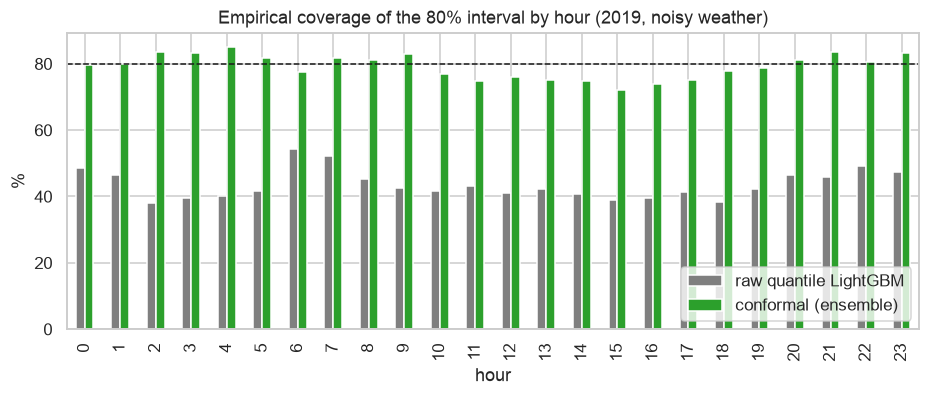

In [13]:
iv = pd.read_csv(RES / "intervals.csv")
iv["mean_width_GW"] = (iv["mean_width_MW"] / 1000).round(2)
display(
    iv.drop(columns="mean_width_MW").pivot_table(
        index=["period", "weather"],
        columns="method",
        values=["coverage_%", "mean_width_GW"],
    )
)
yy = P.actual
lo, hi = P.q_cp_lo__noisy, P.q_cp_hi__noisy
ok = lo.notna()
cov_hour = ((yy >= lo) & (yy <= hi))[ok].groupby(cal.hour[ok]).mean() * 100
raw_cov = ((yy >= P.q10__noisy) & (yy <= P.q90__noisy)).groupby(cal.hour).mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.5))
pd.DataFrame(
    {"raw quantile LightGBM": raw_cov, "conformal (ensemble)": cov_hour}
).plot.bar(ax=ax, color=["tab:gray", "tab:green"])
ax.axhline(80, color="k", ls="--", lw=1)
ax.set(
    title="Empirical coverage of the 80% interval by hour (2019, noisy weather)",
    ylabel="%",
    xlabel="hour",
)
ax.legend(loc="lower right")
save(fig, "16_interval_coverage")

## 11. What drives the model? (SHAP)

Refit the normalised LightGBM on all data up to 2018-12-30 (as in the January 2019 fold) and
explain its 2019 predictions. Values are in units of the normalised target (load / 28-day level).

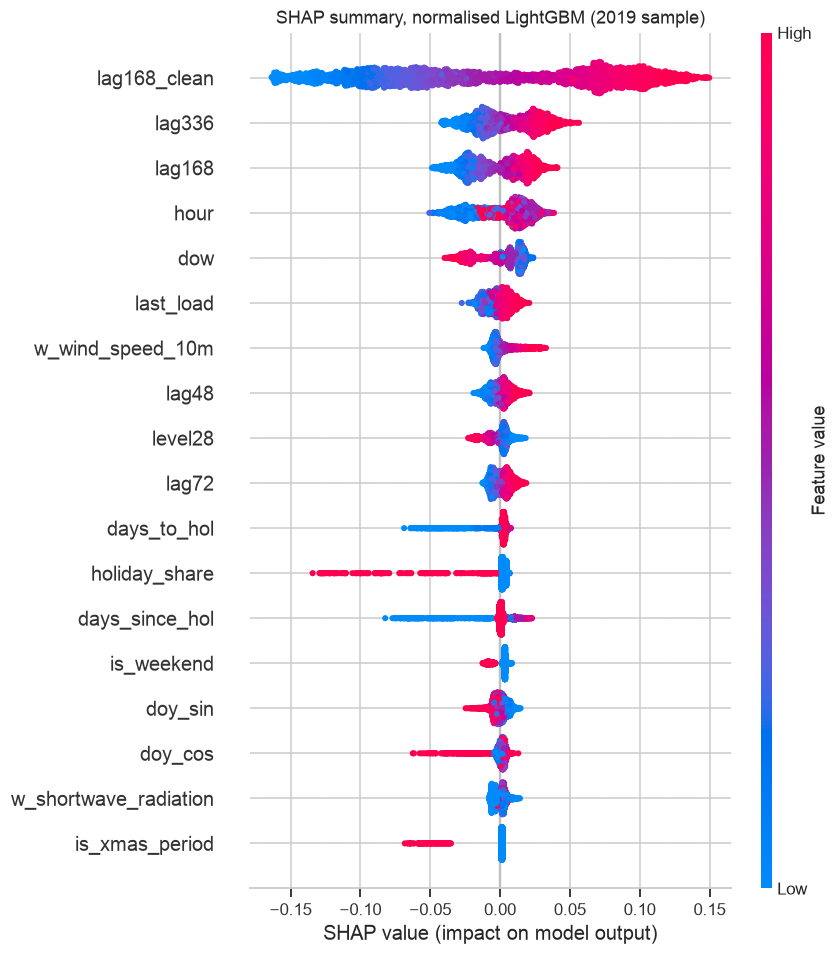

,mean |SHAP| (% of level)
lag168_clean,7.63
lag336,1.84
lag168,1.84
hour,1.69
dow,1.40
last_load,0.68
w_wind_speed_10m,0.55
lag48,0.55
level28,0.55
lag72,0.51


In [14]:
p_norm = {
    k: v for k, v in params["lgbm_norm"].items() if k not in {"val_MAE", "n_trials"}
}
tr = X.loc["2015-02-01":"2018-12-29 23:00"]
ok = tr.notna().all(axis=1)
fm = LGBMForecaster(True, p_norm).fit(tr[ok], y.loc[tr.index][ok])
sample = _normalise(X.loc["2019"]).sample(4000, random_state=0)
explainer = shap.TreeExplainer(fm.model_)
sv = explainer.shap_values(sample)
imp = pd.Series(np.abs(sv).mean(0), index=sample.columns).sort_values(ascending=False)

fig = plt.figure(figsize=(9, 7))
shap.summary_plot(sv, sample, max_display=18, show=False)
plt.title("SHAP summary, normalised LightGBM (2019 sample)")
save(plt.gcf(), "17_shap_summary")
plt.show()
(imp.head(15) * 100).round(2).to_frame("mean |SHAP| (% of level)")

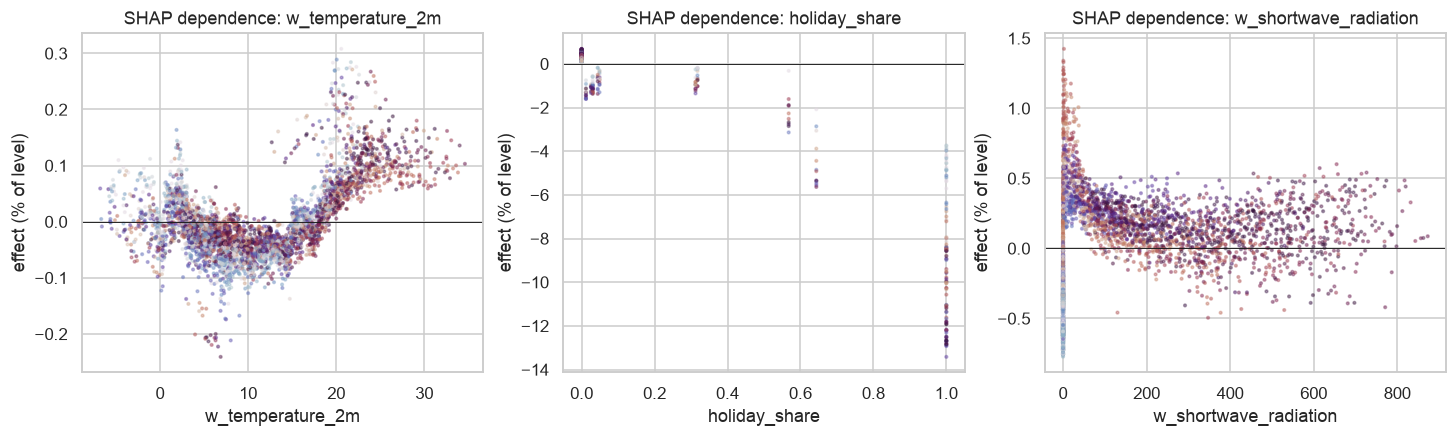

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f in zip(axes, ["w_temperature_2m", "holiday_share", "w_shortwave_radiation"]):
    ax.scatter(
        sample[f],
        sv[:, sample.columns.get_loc(f)] * 100,
        s=3,
        alpha=0.4,
        c=sample["hour"],
        cmap="twilight",
    )
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=f"SHAP dependence: {f}", xlabel=f, ylabel="effect (% of level)")
save(fig, "18_shap_dependence")

## 12. Conclusions

* **Accuracy.** With realistic (noisy) weather, the LightGBM ensemble's MAE is **1.00 GW (1.84 %) in 2019**
  vs **1.99 GW** for the official TSO forecast and **1.55 GW** for the bias-corrected TSO forecast; in
  Jan–Sep 2020: **1.06 GW** vs 1.46 / 1.30 GW. All differences are significant (Diebold-Mariano p < 0.001).
* **Even without any weather data** the ensemble (1.13 GW) beats the bias-corrected TSO forecast — most of
  the edge comes from calendar/holiday modelling and level normalisation; weather adds ~11 % on top,
  and simulated weather-forecast error gives back about a quarter of that.
* **Peak-hour error** halves vs the TSO forecast (1.02 vs 2.14 GW in 2019).
* **Intervals.** Raw quantile LightGBM intervals were badly over-confident (44 % coverage for a nominal
  80 %); online conformal calibration fixes this (≈79–81 %).
* **Caveats.** Weather-forecast errors are simulated; the target series has documented coverage drift;
  OPSD ends in Sep 2020. See `reports/REPORT.md`.